# 08 - Merge and Candidate Selection

Merges all per-residue feature tables (03-07) into one master table, defines Set A (catalytic-adjacent) and Set B (binding-cleft) candidate positions, and generates the figures/tables used in the README.

### Deliverable

A mutation **library specification**: a manageable set of positions per hypothesis, each with suggested residue classes. The goal is not to pinpoint the single best mutation but to define a library small enough to screen. False negatives (dropping a good position) therefore cost more than false positives (one extra well on a plate), and the selection logic is tuned accordingly.

### Selection design

- **Geometry is the only hard gate on positions.** Set A = catalytic-adjacent, Set B = binding-cleft. These encode the two mechanistic hypotheses.
- **Conservation ranks positions *within* each set**, rather than gating globally. A global percentile is confounded by whole-protein composition (a compact functional core with long flexible termini compresses the core's apparent variation), and catalytic proximity is anti-correlated with variability by construction -- gating on both simultaneously left only 1 Set A position.
- **ddG filters mutations, not positions**, with a ceiling rather than a tight guardrail (see the ddG section).
- **Surviving mutations are grouped by physicochemical class**, since a library informative about a binding pocket samples polar/hydrophobic/charged/small/large -- not five conservative variants.

The master table is never row-filtered; all selection lives in added columns.

In [1]:
import sys
sys.path.append("../workflow")

from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from project_utils import load_config, results_dir_for, parse_residue_code

pd.set_option("display.max_columns", 100)

# Target is set by `active_protein` in config/base.yaml.
cfg = load_config()
results_dir = results_dir_for(cfg)
out_dir = results_dir / "08_analysis"
fig_dir = out_dir / "figures"
table_dir = out_dir / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

sel = cfg.get("candidate_selection", {})
CATALYTIC_RADIUS = sel.get("catalytic_radius_angstrom", 10.0)
BINDING_RADIUS = sel.get("binding_site_radius_angstrom", 6.0)
DDG_CEILING = sel.get("ddg_ceiling_kcalmol", 3.5)
WT_DOMINANT_THRESHOLD = sel.get("wt_dominant_frequency_threshold", 0.70)
MIN_MSA_DEPTH = sel.get("min_msa_depth", 30)
NOVELTY_THRESHOLD = sel.get("novelty_frequency_threshold", 0.02)
STRAIN_RELIEF_DDG = sel.get("strain_relief_ddg_threshold", -0.5)

catalytic_positions = [parse_residue_code(c)[1] for c in cfg["functional_residues"]["catalytic"]]
binding_positions = [parse_residue_code(c)[1] for c in cfg["functional_residues"]["binding_site"]]

print(f"Catalytic residues (excluded from all sets): {catalytic_positions}")
print(f"Binding-site reference residues: {binding_positions}")
print(f"Geometry: catalytic radius {CATALYTIC_RADIUS}A, binding radius {BINDING_RADIUS}A")
print(f"ddG ceiling: {DDG_CEILING} kcal/mol")
print(f"WT-dominant threshold: {WT_DOMINANT_THRESHOLD:.0%} | min MSA depth for confidence: {MIN_MSA_DEPTH}")

[config] target: A1CGD1_A  (from A1CGD1.yaml)
Catalytic residues (excluded from all sets): [229, 305]
Binding-site reference residues: [184, 185, 187, 197, 203, 214, 227, 230, 231, 232, 303, 304, 307]
Geometry: catalytic radius 10.0A, binding radius 6.0A
ddG ceiling: 3.5 kcal/mol
WT-dominant threshold: 70% | min MSA depth for confidence: 30


## Load all per-residue tables

In [2]:
cons_df = pd.read_csv(results_dir / "03_conservation" / "conservation_scores.csv")

foldx_df = pd.read_csv(results_dir / "04_foldx_ddg" / "foldx_ddg_scores.csv")
patch_path = results_dir / "04_foldx_ddg" / "foldx_ddg_scores_patch.csv"
if patch_path.exists():
    patch_df = pd.read_csv(patch_path)
    print(f"FoldX patch: {len(patch_df)} recovered position(s) {sorted(patch_df.residue_number.tolist())}")
    foldx_df = pd.concat([foldx_df, patch_df], ignore_index=True)
    assert foldx_df.residue_number.duplicated().sum() == 0, "duplicate residues after patch merge"

geom_df = pd.read_csv(results_dir / "05_bfactor_geometry" / "structural_scores.csv")
sasa_df = pd.read_csv(results_dir / "06_solvent_accessibility" / "sasa_scores.csv")
ss_df = pd.read_csv(results_dir / "07_secondary_structure" / "secondary_structure.csv")

for name, df in [("03_conservation", cons_df), ("04_foldx", foldx_df), ("05_geometry", geom_df),
                  ("06_sasa", sasa_df), ("07_secondary_structure", ss_df)]:
    print(f"{name:25s} {df.shape[0]:4d} rows, residue_number {df.residue_number.min()}-{df.residue_number.max()}")

03_conservation            506 rows, residue_number 1-506
04_foldx                   506 rows, residue_number 1-506
05_geometry                506 rows, residue_number 1-506
06_sasa                    506 rows, residue_number 1-506
07_secondary_structure     506 rows, residue_number 1-506


## Merge

Outer join on `residue_number`, with an explicit `wt_residue` agreement check at every step.

**Two kinds of discrepancy are normal and are reported rather than suppressed:**

- *Residues present in `03` but absent from `04`-`07`.* `03` works from the full UniProt sequence; `04`-`07` work from the structure. Any residue not resolved in the structure — signal peptide, disordered termini, gaps in density — appears in one and not the other. A predicted (AlphaFold) model covers the whole sequence, so this count is usually zero there.
- *`wt_residue` mismatches.* A documented UniProt-vs-structure sequence conflict: the deposited construct genuinely differs from the canonical sequence at that position. Resolved in the next section, where the structure wins.

Anything beyond these two patterns — a mismatch count in the dozens, or residues appearing only in a structural table — means a numbering problem, and should be resolved before trusting anything downstream. `01_acquire_protein.py` runs the same check against UniProt and will usually catch it first.

In [3]:
def merge_with_check(base, other, name):
    only_base = set(base.residue_number) - set(other.residue_number)
    only_other = set(other.residue_number) - set(base.residue_number)
    if only_base:
        print(f"  {len(only_base)} residues absent from {name}: {sorted(only_base)[:8]}...")
    if only_other:
        print(f"  {len(only_other)} residues only in {name}: {sorted(only_other)[:8]}...")

    merged = base.merge(other, on="residue_number", how="outer", suffixes=("", f"_{name}"))
    check_col = f"wt_residue_{name}"
    if check_col in merged.columns:
        both = merged["wt_residue"].notna() & merged[check_col].notna()
        n_mismatch = (both & (merged["wt_residue"] != merged[check_col])).sum()
        print(f"  wt_residue: {n_mismatch} mismatches of {both.sum()} overlapping")
        merged["wt_residue"] = merged["wt_residue"].fillna(merged[check_col])
        merged = merged.drop(columns=[check_col])
    return merged

master = cons_df.copy()
for name, df in [("04_foldx", foldx_df), ("05_geometry", geom_df),
                  ("06_sasa", sasa_df), ("07_secondary_structure", ss_df)]:
    print(f"Merging {name}...")
    master = merge_with_check(master, df, name)

master = master.sort_values("residue_number").reset_index(drop=True)
print(f"\nMaster table: {master.shape[0]} residues x {master.shape[1]} columns")

Merging 04_foldx...
  wt_residue: 0 mismatches of 506 overlapping
Merging 05_geometry...
  wt_residue: 0 mismatches of 506 overlapping
Merging 06_sasa...
  wt_residue: 0 mismatches of 506 overlapping
Merging 07_secondary_structure...
  wt_residue: 0 mismatches of 506 overlapping

Master table: 506 residues x 91 columns


## Resolve sequence-source conflicts: structure wins

`03`'s `wt_residue` comes from the UniProt query sequence; `04`-`07` from the crystal structure. Every biophysical measurement downstream was computed on the structure's atoms, so the structure is the only internally-consistent choice. UniProt identity is kept alongside rather than discarded.

In [4]:
master = master.rename(columns={"wt_residue": "wt_residue_uniprot"})
struct_wt = geom_df.set_index("residue_number")["wt_residue"]
master["wt_residue"] = master["residue_number"].map(struct_wt).fillna(master["wt_residue_uniprot"])
master["is_modeled_in_structure"] = master["residue_number"].isin(struct_wt.index)
master["uniprot_structure_conflict"] = (
    master["wt_residue_uniprot"].notna() & master["wt_residue"].notna()
    & (master["wt_residue_uniprot"] != master["wt_residue"])
)
master["cons_is_conserved_as_wt"] = master["wt_residue"] == master["cons_predominant_residue"]

def _wt_natural_freq(row):
    col = f"cons_freq_unweighted_{row['wt_residue']}"
    return row[col] if col in row.index and pd.notna(row["wt_residue"]) else np.nan

master["wt_natural_frequency"] = master.apply(_wt_natural_freq, axis=1)

n = master["uniprot_structure_conflict"].sum()
print(f"{n} UniProt/structure conflicts")
if n:
    display(master.loc[master["uniprot_structure_conflict"],
                        ["residue_number", "wt_residue_uniprot", "wt_residue",
                         "cons_predominant_residue", "wt_natural_frequency"]])

master.to_csv(out_dir / "master_residue_table.csv", index=False)
print(f"\nSaved master table -> {out_dir / 'master_residue_table.csv'}")

0 UniProt/structure conflicts

Saved master table -> N:\Jupiter_Projects\rational-enzyme-engineering\results\A1CGD1_A\08_analysis\master_residue_table.csv


## Stage 1: raw distributions

Note: a conservation *percentile* is uniform by construction and can never show a natural break to threshold on. Entropy (bits) is the distribution with real structure, and is what the within-set ranking below uses.

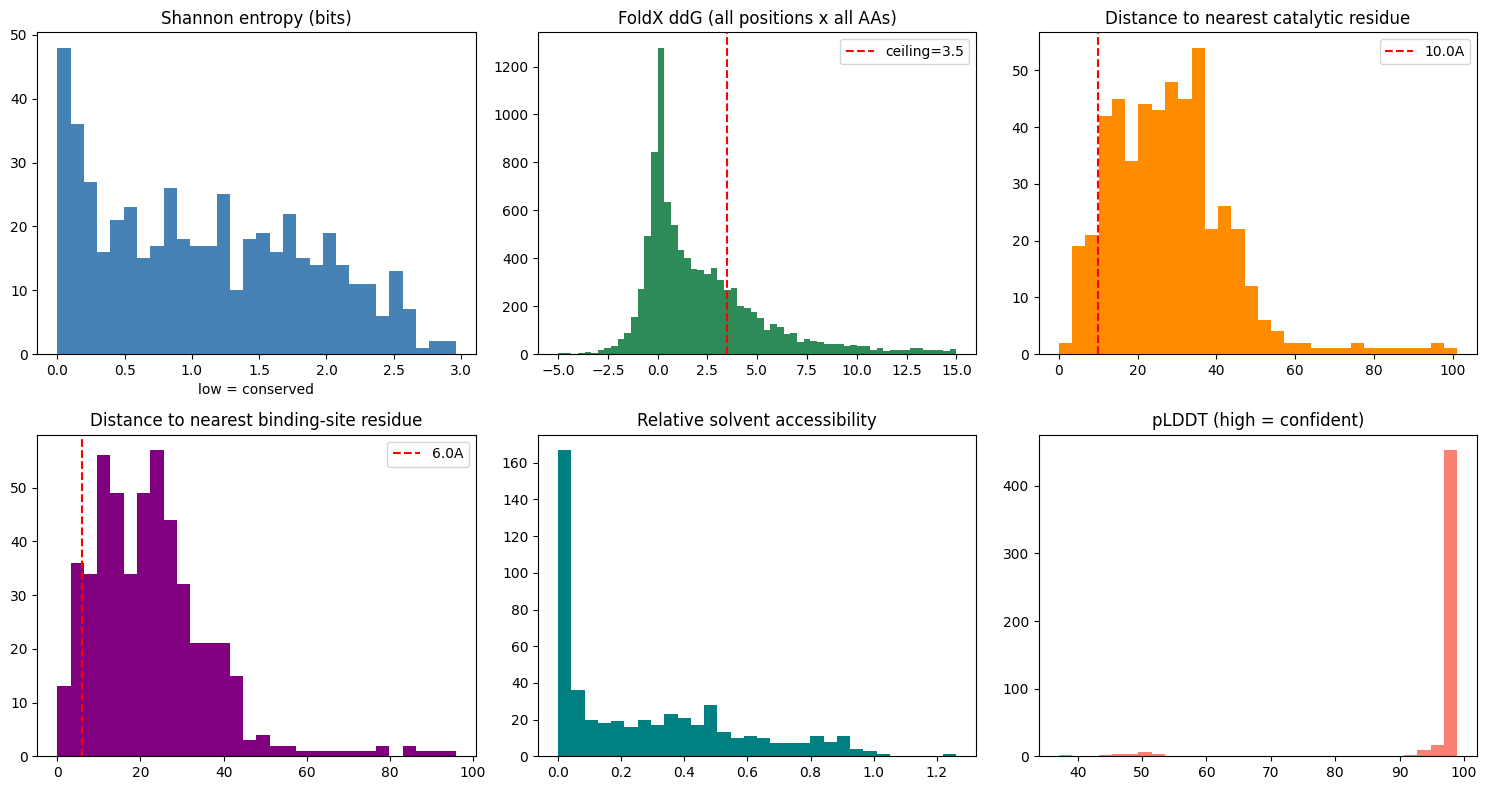

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].hist(master["cons_shannon_entropy"].dropna(), bins=30, color="steelblue")
axes[0, 0].set_title("Shannon entropy (bits)")
axes[0, 0].set_xlabel("low = conserved")

ddg_cols = [c for c in master.columns if c.startswith("foldx_ddg_")]
all_ddg = master[ddg_cols].values.flatten()
all_ddg = all_ddg[~np.isnan(all_ddg)]
axes[0, 1].hist(all_ddg, bins=60, range=(-5, 15), color="seagreen")
axes[0, 1].axvline(DDG_CEILING, color="red", linestyle="--", label=f"ceiling={DDG_CEILING}")
axes[0, 1].set_title("FoldX ddG (all positions x all AAs)"); axes[0, 1].legend()

axes[0, 2].hist(master["struct_dist_nearest_catalytic"].dropna(), bins=30, color="darkorange")
axes[0, 2].axvline(CATALYTIC_RADIUS, color="red", linestyle="--", label=f"{CATALYTIC_RADIUS}A")
axes[0, 2].set_title("Distance to nearest catalytic residue"); axes[0, 2].legend()

axes[1, 0].hist(master["struct_dist_nearest_binding_site"].dropna(), bins=30, color="purple")
axes[1, 0].axvline(BINDING_RADIUS, color="red", linestyle="--", label=f"{BINDING_RADIUS}A")
axes[1, 0].set_title("Distance to nearest binding-site residue"); axes[1, 0].legend()

axes[1, 1].hist(master["struct_rsa"].dropna(), bins=30, color="teal")
axes[1, 1].set_title("Relative solvent accessibility")

# For a predicted model this column is pLDDT (high = confident), not a
# crystallographic B-factor (high = mobile). 05 renames it accordingly.
if "struct_plddt" in master.columns:
    axes[1, 2].hist(master["struct_plddt"].dropna(), bins=30, color="salmon")
    axes[1, 2].set_title("pLDDT (high = confident)")
else:
    axes[1, 2].hist(master["struct_bfactor_ca"].dropna(), bins=30, color="salmon")
    axes[1, 2].set_title("CA B-factor (raw)")

plt.tight_layout()
plt.savefig(fig_dir / "raw_distributions.png", dpi=150)
plt.show()

## Stage 2: geometric sets (hard gate) + within-set conservation ranking

In [6]:
master["is_catalytic"] = master["residue_number"].isin(catalytic_positions)
master["is_binding_site_residue"] = master["residue_number"].isin(binding_positions)

near_catalytic = (master["struct_dist_nearest_catalytic"] <= CATALYTIC_RADIUS) & (~master["is_catalytic"])
near_binding = (master["struct_dist_nearest_binding_site"] <= BINDING_RADIUS) & (~master["is_catalytic"])

# For a predicted structure, exclude positions the model is not confident about.
# Their geometry, SASA and ddG are all unreliable, so they must not enter the
# candidate sets even if they happen to fall within the distance cutoffs.
if "struct_confidence_ok" in master.columns:
    confident = master["struct_confidence_ok"].fillna(False)
    n_excluded = int((~confident & (near_catalytic | near_binding)).sum())
    print(f"Predicted structure: excluding {n_excluded} low-pLDDT position(s) "
          f"that would otherwise qualify geometrically.")
    near_catalytic = near_catalytic & confident
    near_binding = near_binding & confident

master["geom_set_a"] = near_catalytic
master["geom_set_b"] = near_binding & (~near_catalytic)   # Set A takes priority on overlap
master["geometric_set"] = np.where(master["geom_set_a"], "A",
                            np.where(master["geom_set_b"], "B", ""))

# --- Tiering ---------------------------------------------------------------
# Tier 1 = wild-type residue is NOT already dominant among homologs, i.e. this
#   protein's residue differs from what the family typically uses, or the column
#   is genuinely variable. These are the primary engineering targets.
# Tier 2 = wild-type is dominant (>= threshold). Evolution has converged here,
#   so these are deprioritised -- but NOT discarded, because conservation
#   depends on how many homologs were found, which varies by protein.
#
# Threshold uses UNWEIGHTED frequency: it is an observational question
# ("how often does nature actually use this residue here?"), directly
# checkable by a reader against the alignment.
#
# There is no canonical value in the literature -- consensus-design studies
# use a range of cutoffs -- so this is a reported, configurable choice rather
# than a principled constant.
master["wt_is_dominant"] = master["wt_natural_frequency"] >= WT_DOMINANT_THRESHOLD
master["tier"] = np.where(master["wt_is_dominant"], 2, 1)

# Alignment depth caveat: a shallow column makes any conservation call unreliable.
master["cons_depth_ok"] = master["cons_n_sequences_observed"] >= MIN_MSA_DEPTH

# Rank within each geometric set, tier 1 first, then by entropy (high = variable).
for set_col, rank_col in [("geom_set_a", "set_a_rank"), ("geom_set_b", "set_b_rank")]:
    subset = master[master[set_col]].copy()
    order = subset.sort_values(["tier", "cons_shannon_entropy"],
                                ascending=[True, False]).index
    master.loc[order, rank_col] = range(1, len(order) + 1)

print(f"Geometric gate:  Set A {master['geom_set_a'].sum()} positions | "
      f"Set B {master['geom_set_b'].sum()} positions")
print(f"\nTier split within each set (tier 1 = WT not dominant, primary targets):")
for label, col in [("Set A", "geom_set_a"), ("Set B", "geom_set_b")]:
    sub = master[master[col]]
    print(f"  {label}: tier 1 = {(sub['tier']==1).sum()}, tier 2 = {(sub['tier']==2).sum()}, "
          f"low MSA depth = {(~sub['cons_depth_ok']).sum()}")

print(f"\nEntropy within each geometric set:")
for label, col in [("Set A", "geom_set_a"), ("Set B", "geom_set_b")]:
    e = master.loc[master[col], "cons_shannon_entropy"]
    print(f"  {label}: min={e.min():.2f} median={e.median():.2f} max={e.max():.2f} "
          f"(whole protein median={master['cons_shannon_entropy'].median():.2f})")

Predicted structure: excluding 0 low-pLDDT position(s) that would otherwise qualify geometrically.
Geometric gate:  Set A 38 positions | Set B 17 positions

Tier split within each set (tier 1 = WT not dominant, primary targets):
  Set A: tier 1 = 6, tier 2 = 32, low MSA depth = 0
  Set B: tier 1 = 6, tier 2 = 11, low MSA depth = 0

Entropy within each geometric set:
  Set A: min=-0.00 median=0.70 max=2.78 (whole protein median=1.02)
  Set B: min=-0.00 median=0.79 max=2.65 (whole protein median=1.02)


### Do the two sets need different ddG ceilings?

There is no strong mechanistic case for a stricter Set B ceiling -- analyses of directed-evolution mutations find that substrate-binding-pocket mutations carry a *larger* stability burden than neutral surface mutations, not a smaller one. But Set B is more solvent-exposed, and exposed positions produce smaller ddG effects almost by definition, so a single shared ceiling may bite less there anyway. Checked rather than assumed.

In [7]:
def set_ddg_values(df, set_col):
    vals = df.loc[df[set_col], ddg_cols].values.flatten()
    return vals[~np.isnan(vals)]

a_ddg, b_ddg = set_ddg_values(master, "geom_set_a"), set_ddg_values(master, "geom_set_b")
display(pd.DataFrame({
    "Set A (catalytic-adjacent)": pd.Series(a_ddg).describe(),
    "Set B (binding cleft)": pd.Series(b_ddg).describe(),
}).round(2))
print(f"Fraction above ceiling ({DDG_CEILING}):  "
      f"Set A {np.mean(a_ddg > DDG_CEILING):.1%} | Set B {np.mean(b_ddg > DDG_CEILING):.1%}")
print("\nBurial composition (explains any difference above):")
display(pd.DataFrame({
    "Set A": master.loc[master["geom_set_a"], "struct_burial_class"].value_counts(),
    "Set B": master.loc[master["geom_set_b"], "struct_burial_class"].value_counts(),
}).fillna(0).astype(int))

,Set A (catalytic-adjacent),Set B (binding cleft)
count,760.00,340.00
mean,5.62,4.43
std,12.23,7.01
min,-6.81,-5.97
25%,0.02,0.15
50%,2.13,2.55
75%,5.24,5.48
max,78.83,46.59


Fraction above ceiling (3.5):  Set A 36.2% | Set B 40.3%

Burial composition (explains any difference above):


,Set A,Set B
struct_burial_class,,
buried,18,11
exposed,14,6
intermediate,6,0


## Mutation-level selection

**ddG ceiling of 3.5 kcal/mol**, not a tight guardrail. Two anchors: FoldX's reported accuracy is ~0.5 kcal/mol standard deviation against experiment (and it is less reliable in the large-destabilizing tail), and a typical globular protein carries only ~5-15 kcal/mol of total folding free energy, so a single +4 mutation spends a serious fraction of the budget. The ceiling excludes the tail running past +15 while retaining moderately destabilizing mutations -- which the stability-function tradeoff literature identifies as exactly where activity gains often live.

**Physicochemical classes:** for each position the best-ranked surviving mutation from each class is reported, so the library samples property space rather than five conservative variants.

**Strain-relief flag** (Set A, buried and intermediate positions only): a stabilising substitution near a catalytic site may be relieving functional strain -- the classic observation is that catalytic-residue substitutions which stabilise an enzyme by several kcal/mol cut activity by orders of magnitude. Flagged rather than filtered, since that evidence comes from catalytic residues themselves (already excluded here) and extending it to second-shell residues is an inference the data does not directly support.

Restricted by burial because the raw flag turned out to be measuring the wrong thing at exposed positions. Within a single target and structure, the fraction of substitutions below -0.5 kcal/mol tracks burial closely: ~6% at buried positions (median ddG ~4.0) against ~16-20% at exposed ones (median ~0.3). An exposed loop residue has no packing to disrupt, so substitutions are near-neutral and ordinary scatter pushes many below the threshold. Unrestricted, the flag would mostly report solvent exposure rather than strain.

In [8]:
AA_CLASS = {
    "A": "small", "G": "small",
    "V": "hydrophobic", "L": "hydrophobic", "I": "hydrophobic", "M": "hydrophobic",
    "F": "aromatic", "W": "aromatic", "Y": "aromatic",
    "S": "polar", "T": "polar", "N": "polar", "Q": "polar", "C": "polar",
    "K": "positive", "R": "positive", "H": "positive",
    "D": "negative", "E": "negative",
    "P": "special",
}
ALL_AAS = list("ACDEFGHIKLMNPQRSTVWY")

def build_mutation_table(df, set_col, set_label, rank_col, flag_strain_relief=False):
    """Every substitution at every position in the geometric set, with an
    explicit exclusion reason where applicable -- nothing disappears silently."""
    rows, dropped_positions = [], []
    for _, r in df[df[set_col]].iterrows():
        n_kept = 0
        for aa in ALL_AAS:
            if aa == r["wt_residue"]:
                continue
            ddg = r.get(f"foldx_ddg_{aa}")
            if pd.isna(ddg):
                continue
            passes = ddg <= DDG_CEILING
            n_kept += int(passes)
            # NOTE: ddG is reported and ranked, never used to exclude. On both
            # validation targets the experimentally-confirmed activity-improving
            # mutation was among the MORE destabilising options at its position
            # (S538V +2.65; R243A +4.66), so a hard ceiling removes exactly the
            # mutations being searched for.
            freq = r.get(f"cons_freq_unweighted_{aa}", np.nan)
            rows.append({
                "set": set_label,
                "tier": int(r["tier"]),
                "position_rank": r.get(rank_col),
                "residue_number": int(r["residue_number"]),
                "wt_residue": r["wt_residue"],
                "mutant": aa,
                "mutation": f"{r['wt_residue']}{int(r['residue_number'])}{aa}",
                "aa_class": AA_CLASS[aa],
                "foldx_ddg": round(float(ddg), 2),
                "passes_ddg_ceiling": bool(passes),
                "natural_frequency": freq,
                "is_novel_substitution": bool(pd.notna(freq) and freq < NOVELTY_THRESHOLD),
                # Restricted to buried/intermediate positions. At exposed
                # positions a negative ddG mostly reflects the absence of
                # packing to disrupt rather than relieved functional strain:
                # measured on this target, ~6% of substitutions at buried
                # positions fall below -0.5 kcal/mol against ~16-20% at exposed
                # ones, with median ddG ~4.0 vs ~0.3. Without the restriction
                # the flag would mostly be reporting solvent exposure.
                "strain_relieving_candidate": bool(
                    flag_strain_relief and ddg < STRAIN_RELIEF_DDG
                    and r["struct_burial_class"] in ("buried", "intermediate")),
                "wt_natural_frequency": r["wt_natural_frequency"],
                "cons_shannon_entropy": r["cons_shannon_entropy"],
                "cons_depth_ok": bool(r["cons_depth_ok"]),
                "struct_dist_nearest_catalytic": round(float(r["struct_dist_nearest_catalytic"]), 2),
                "struct_dist_nearest_binding_site": round(float(r["struct_dist_nearest_binding_site"]), 2),
                "struct_burial_class": r["struct_burial_class"],
                "struct_ss_class": r["struct_ss_class"],
            })
        if n_kept == 0:
            dropped_positions.append({
                "residue_number": int(r["residue_number"]),
                "wt_residue": r["wt_residue"],
                "reason": f"no substitution below ddG ceiling ({DDG_CEILING})",
                "min_ddg_available": round(float(min(
                    r.get(f"foldx_ddg_{a}") for a in ALL_AAS
                    if a != r["wt_residue"] and pd.notna(r.get(f"foldx_ddg_{a}")))), 2),
                "struct_burial_class": r["struct_burial_class"],
                "struct_ss_class": r["struct_ss_class"],
            })
    out = pd.DataFrame(rows)
    if len(out):
        out = out.sort_values(["position_rank", "foldx_ddg"]).reset_index(drop=True)
    return out, pd.DataFrame(dropped_positions)

def add_ddg_ranks(muts):
    """Rank substitutions by predicted destabilisation, within position and
    within set. Reported as ordering information, not a filter."""
    if not len(muts):
        return muts
    muts = muts.copy()
    muts["ddg_rank_in_position"] = muts.groupby("residue_number")["foldx_ddg"].rank(method="min")
    muts["ddg_percentile_in_set"] = 100 * muts["foldx_ddg"].rank(pct=True)
    return muts


muts_a, dropped_a = build_mutation_table(master, "geom_set_a", "A", "set_a_rank", flag_strain_relief=True)
muts_b, dropped_b = build_mutation_table(master, "geom_set_b", "B", "set_b_rank", flag_strain_relief=False)

muts_a, muts_b = add_ddg_ranks(muts_a), add_ddg_ranks(muts_b)

for label, m, d in [("Set A", muts_a, dropped_a), ("Set B", muts_b, dropped_b)]:
    viable = m[m.passes_ddg_ceiling]
    print(f"{label}: {m.residue_number.nunique()} positions evaluated, "
          f"{len(viable)} viable mutations across {viable.residue_number.nunique()} positions "
          f"({viable.is_novel_substitution.sum()} novel to nature)")
    if len(d):
        print(f"  {len(d)} position(s) with NO viable substitution:")
        display(d)

if len(muts_a):
    sr = muts_a[muts_a.passes_ddg_ceiling]
    print(f"\nSet A strain-relief candidates (ddG < {STRAIN_RELIEF_DDG}, "
          f"buried/intermediate only): {int(sr.strain_relieving_candidate.sum())}")
    exposed_neg = int(((sr.foldx_ddg < STRAIN_RELIEF_DDG)
                        & (sr.struct_burial_class == "exposed")).sum())
    if exposed_neg:
        print(f"    ({exposed_neg} further stabilising substitution(s) at exposed "
              f"positions, not flagged -- at exposed positions a negative ddG "
              f"mostly reflects the absence of packing to disrupt)")

Set A: 38 positions evaluated, 448 viable mutations across 35 positions (403 novel to nature)
  3 position(s) with NO viable substitution:


,residue_number,wt_residue,reason,min_ddg_available,struct_burial_class,struct_ss_class
0,115,G,no substitution below ddG ceiling (3.5),7.34,exposed,loop
1,201,G,no substitution below ddG ceiling (3.5),4.74,buried,loop
2,202,H,no substitution below ddG ceiling (3.5),58.61,intermediate,loop


Set B: 17 positions evaluated, 186 viable mutations across 16 positions (154 novel to nature)
  1 position(s) with NO viable substitution:


,residue_number,wt_residue,reason,min_ddg_available,struct_burial_class,struct_ss_class
0,301,G,no substitution below ddG ceiling (3.5),4.83,buried,loop



Set A strain-relief candidates (ddG < -0.5, buried/intermediate only): 49
    (55 further stabilising substitution(s) at exposed positions, not flagged -- at exposed positions a negative ddG mostly reflects the absence of packing to disrupt)


### Library specification: best representative per physicochemical class

In [9]:
def library_spec(muts):
    """Per position, the lowest-ddG mutation from each physicochemical class.

    ddG orders candidates within a class; it does not exclude any. Full ranked
    output, no top-N cut -- the user knows their own selection platform's
    capacity and can cut the ranked list where it fits."""
    if not len(muts):
        return pd.DataFrame()
    best = (muts.sort_values("foldx_ddg")
                  .groupby(["residue_number", "aa_class"], as_index=False)
                  .first())
    return best.sort_values(["position_rank", "foldx_ddg"]).reset_index(drop=True)

lib_a, lib_b = library_spec(muts_a), library_spec(muts_b)

for label, lib in [("Set A", lib_a), ("Set B", lib_b)]:
    if len(lib):
        t1 = lib[lib.tier == 1]
        print(f"{label} library: {len(lib)} variants across {lib.residue_number.nunique()} positions "
              f"| tier 1: {len(t1)} variants across {t1.residue_number.nunique()} positions")

muts_a.to_csv(table_dir / "set_a_all_mutations.csv", index=False)
muts_b.to_csv(table_dir / "set_b_all_mutations.csv", index=False)
lib_a.to_csv(table_dir / "set_a_library_spec.csv", index=False)
lib_b.to_csv(table_dir / "set_b_library_spec.csv", index=False)
if len(dropped_a): dropped_a.to_csv(table_dir / "set_a_dropped_positions.csv", index=False)
if len(dropped_b): dropped_b.to_csv(table_dir / "set_b_dropped_positions.csv", index=False)

show_cols = ["position_rank", "tier", "mutation", "aa_class", "foldx_ddg",
             "natural_frequency", "is_novel_substitution", "wt_natural_frequency",
             "struct_burial_class", "struct_ss_class"]
print("\nSet A library (ranked; tier 1 first):")
display(lib_a[show_cols] if len(lib_a) else "none")

Set A library: 265 variants across 38 positions | tier 1: 42 variants across 6 positions
Set B library: 119 variants across 17 positions | tier 1: 42 variants across 6 positions

Set A library (ranked; tier 1 first):


,position_rank,tier,mutation,aa_class,foldx_ddg,natural_frequency,is_novel_substitution,wt_natural_frequency,struct_burial_class,struct_ss_class
0,1.0,1,L196R,positive,-0.94,0.306122,False,0.219388,exposed,loop
1,1.0,1,L196F,aromatic,0.04,0.000000,True,0.219388,exposed,loop
2,1.0,1,L196Q,polar,0.11,0.015306,True,0.219388,exposed,loop
3,1.0,1,L196I,hydrophobic,0.16,0.000000,True,0.219388,exposed,loop
4,1.0,1,L196E,negative,0.76,0.000000,True,0.219388,exposed,loop
...,...,...,...,...,...,...,...,...,...,...
260,38.0,2,N306G,small,2.41,0.000000,True,1.000000,buried,loop
261,38.0,2,N306L,hydrophobic,2.89,0.000000,True,1.000000,buried,loop
262,38.0,2,N306E,negative,6.33,0.000000,True,1.000000,buried,loop
263,38.0,2,N306F,aromatic,11.51,0.000000,True,1.000000,buried,loop


In [10]:
print("Set B library (ranked; tier 1 first):")
display(lib_b[show_cols] if len(lib_b) else "none")

Set B library (ranked; tier 1 first):


,position_rank,tier,mutation,aa_class,foldx_ddg,natural_frequency,is_novel_substitution,wt_natural_frequency,struct_burial_class,struct_ss_class
0,1.0,1,V213R,positive,-1.46,0.005181,True,0.404145,exposed,loop
1,1.0,1,V213M,hydrophobic,-0.93,0.000000,True,0.404145,exposed,loop
2,1.0,1,V213E,negative,-0.78,0.015544,True,0.404145,exposed,loop
3,1.0,1,V213Q,polar,-0.67,0.005181,True,0.404145,exposed,loop
4,1.0,1,V213F,aromatic,-0.09,0.025907,False,0.404145,exposed,loop
...,...,...,...,...,...,...,...,...,...,...
114,17.0,2,G301D,negative,11.53,0.000000,True,1.000000,buried,loop
115,17.0,2,G301V,hydrophobic,12.75,0.000000,True,1.000000,buried,loop
116,17.0,2,G301P,special,13.13,0.000000,True,1.000000,buried,loop
117,17.0,2,G301F,aromatic,19.70,0.000000,True,1.000000,buried,loop


## Selected positions overview

In [11]:
pos_cols = ["residue_number", "wt_residue", "cons_shannon_entropy", "cons_conservation_percentile",
            "struct_dist_nearest_catalytic", "struct_dist_nearest_binding_site",
            "struct_burial_class", "struct_ss_class"]
# Flexibility/confidence column depends on the structure source: a predicted
# model carries pLDDT, an experimental one a B-factor percentile.
pos_cols += [c for c in ("struct_plddt", "struct_bfactor_ca_percentile")
             if c in master.columns]
pos_cols += [c for c in ("struct_in_disulfide",) if c in master.columns]

for label, col, rank_col in [("Set A (catalytic-adjacent)", "geom_set_a", "set_a_rank"),
                              ("Set B (binding cleft)", "geom_set_b", "set_b_rank")]:
    sub = master[master[col]].sort_values(rank_col)
    print(f"\n{label}: {len(sub)} positions")
    display(sub[pos_cols + [rank_col, "tier", "wt_natural_frequency", "cons_depth_ok"]].round(2))


Set A (catalytic-adjacent): 38 positions


,residue_number,wt_residue,cons_shannon_entropy,cons_conservation_percentile,struct_dist_nearest_catalytic,struct_dist_nearest_binding_site,struct_burial_class,struct_ss_class,struct_plddt,struct_in_disulfide,set_a_rank,tier,wt_natural_frequency,cons_depth_ok
195,196,L,2.78,0.59,4.07,3.81,exposed,loop,98.75,False,1.0,1,0.22,True
117,118,K,2.31,7.31,9.38,8.01,exposed,loop,98.62,False,2.0,1,0.15,True
194,195,S,1.81,21.74,4.80,5.77,buried,loop,98.75,False,3.0,1,0.65,True
197,198,T,1.74,24.51,8.07,3.85,exposed,loop,98.69,False,4.0,1,0.70,True
307,308,N,1.50,33.20,8.89,3.83,intermediate,loop,98.75,False,5.0,1,0.50,True
193,194,S,1.49,33.60,8.12,8.22,exposed,loop,98.56,False,6.0,1,0.44,True
116,117,F,2.22,8.89,6.37,5.65,exposed,loop,98.62,False,7.0,2,0.85,True
201,202,H,1.56,30.83,5.94,3.87,intermediate,loop,98.88,False,8.0,2,0.72,True
227,228,L,1.35,37.94,3.88,3.83,buried,loop,98.81,False,9.0,2,0.96,True
192,193,T,1.08,47.83,9.65,8.55,exposed,loop,98.81,False,10.0,2,0.81,True



Set B (binding cleft): 17 positions


,residue_number,wt_residue,cons_shannon_entropy,cons_conservation_percentile,struct_dist_nearest_catalytic,struct_dist_nearest_binding_site,struct_burial_class,struct_ss_class,struct_plddt,struct_in_disulfide,set_b_rank,tier,wt_natural_frequency,cons_depth_ok
212,213,V,2.65,0.99,12.54,3.85,exposed,loop,97.81,False,1.0,1,0.40,True
238,239,A,2.57,2.17,14.17,5.95,exposed,loop,96.50,False,2.0,1,0.08,True
182,183,G,2.48,4.35,13.44,3.82,exposed,loop,98.12,False,3.0,1,0.68,True
308,309,G,2.30,7.71,11.73,5.23,exposed,loop,98.56,False,4.0,1,0.59,True
309,310,A,1.59,29.84,12.95,4.93,buried,loop,98.81,False,5.0,1,0.66,True
211,212,T,1.12,47.23,14.44,5.33,exposed,loop,98.00,False,6.0,1,0.53,True
213,214,W,1.43,35.18,10.35,0.00,exposed,loop,98.06,False,7.0,2,0.88,True
224,225,M,1.20,43.28,11.77,5.93,buried,sheet,98.88,False,8.0,2,0.88,True
205,206,I,0.79,59.68,11.55,5.32,buried,sheet,98.94,False,9.0,2,0.86,True
187,188,Y,0.75,60.87,12.85,3.81,buried,sheet,98.94,False,10.0,2,0.98,True


## Validation against published mutagenesis

Only meaningful for a target with measured mutational data; skipped automatically otherwise, which is the expected path for a novel target.

Run **after** the candidate sets are built — none of the cutoffs above are tuned against these positions. Known sites are held in a lookup table keyed by PDB ID in the next cell; add an entry there to check a new target.

The quantitative validation of this pipeline is not here but in [`validation/bglb_kinetic_validation.ipynb`](../validation/bglb_kinetic_validation.ipynb), which compares the ranking against 100 measured mutants rather than a handful of known positions.

In [12]:
# Known-site check. Only meaningful for a target with published mutagenesis
# data; skipped otherwise. Run AFTER the fact, never used to tune any cutoff.
#
# 1CTN (S. marcescens chitinase A, Visootsat et al. 2020) was the original
# development target. Its sites are kept here for reference but the pipeline's
# quantitative validation is the BglB kinetic comparison in
# validation/bglb_kinetic_validation.ipynb -- 100 measured mutants rather than
# a single confirmed hit.
KNOWN_SITES = {
    "1CTN": {"sites": [70, 162, 238, 397, 441, 476, 538, 551],
             "hit": (538, "V"), "assayed": ["V", "A", "G", "T"],
             "note": "S538V improved activity; S538A/G/T did not"},
    "2JIE": {"sites": [225, 243], "hit": (243, "A"), "assayed": ["A", "K", "D"],
             "note": "R243A ~12x kcat; E225A ~10x decrease (R240A/E222A in paper numbering)"},
}

target_pdb = cfg["protein"]["pdb_id"].upper()
known = KNOWN_SITES.get(target_pdb)

if not known:
    print(f"No published mutagenesis data configured for {target_pdb} -- "
          f"nothing to check against.\n"
          f"This is the expected path for a novel target: the output below is a "
          f"prediction, not a validated result.")
else:
    print(f"{target_pdb}: {known['note']}\n")
    cols = [c for c in ["residue_number", "wt_residue", "cons_shannon_entropy",
                         "cons_conservation_percentile", "struct_dist_nearest_catalytic",
                         "struct_dist_nearest_binding_site", "geom_set_a", "geom_set_b",
                         "set_a_rank", "set_b_rank", "tier", "wt_natural_frequency"]
            if c in master.columns]
    display(master[master.residue_number.isin(known["sites"])][cols].round(2))

    pos, mut = known["hit"]
    r = master[master.residue_number == pos]
    if len(r):
        r = r.iloc[0]
        n_setb = int(master["geom_set_b"].sum())
        print(f"\nPosition {pos} ({r['wt_residue']}): Set A={r['geom_set_a']}, "
              f"Set B={r['geom_set_b']}, tier {int(r['tier'])}, "
              f"Set B rank {r['set_b_rank']} of {n_setb}")
        print(f"\n  ddG for the substitutions assayed in the paper:")
        for aa in known["assayed"]:
            ddg = r.get(f"foldx_ddg_{aa}")
            freq = r.get(f"cons_freq_unweighted_{aa}")
            if pd.notna(ddg):
                print(f"    {r['wt_residue']}{pos}{aa}: ddG={ddg:+.2f}, "
                      f"natural_freq={freq:.3f}")

No published mutagenesis data configured for A1CGD1 -- nothing to check against.
This is the expected path for a novel target: the output below is a prediction, not a validated result.


## Multi-track position plot

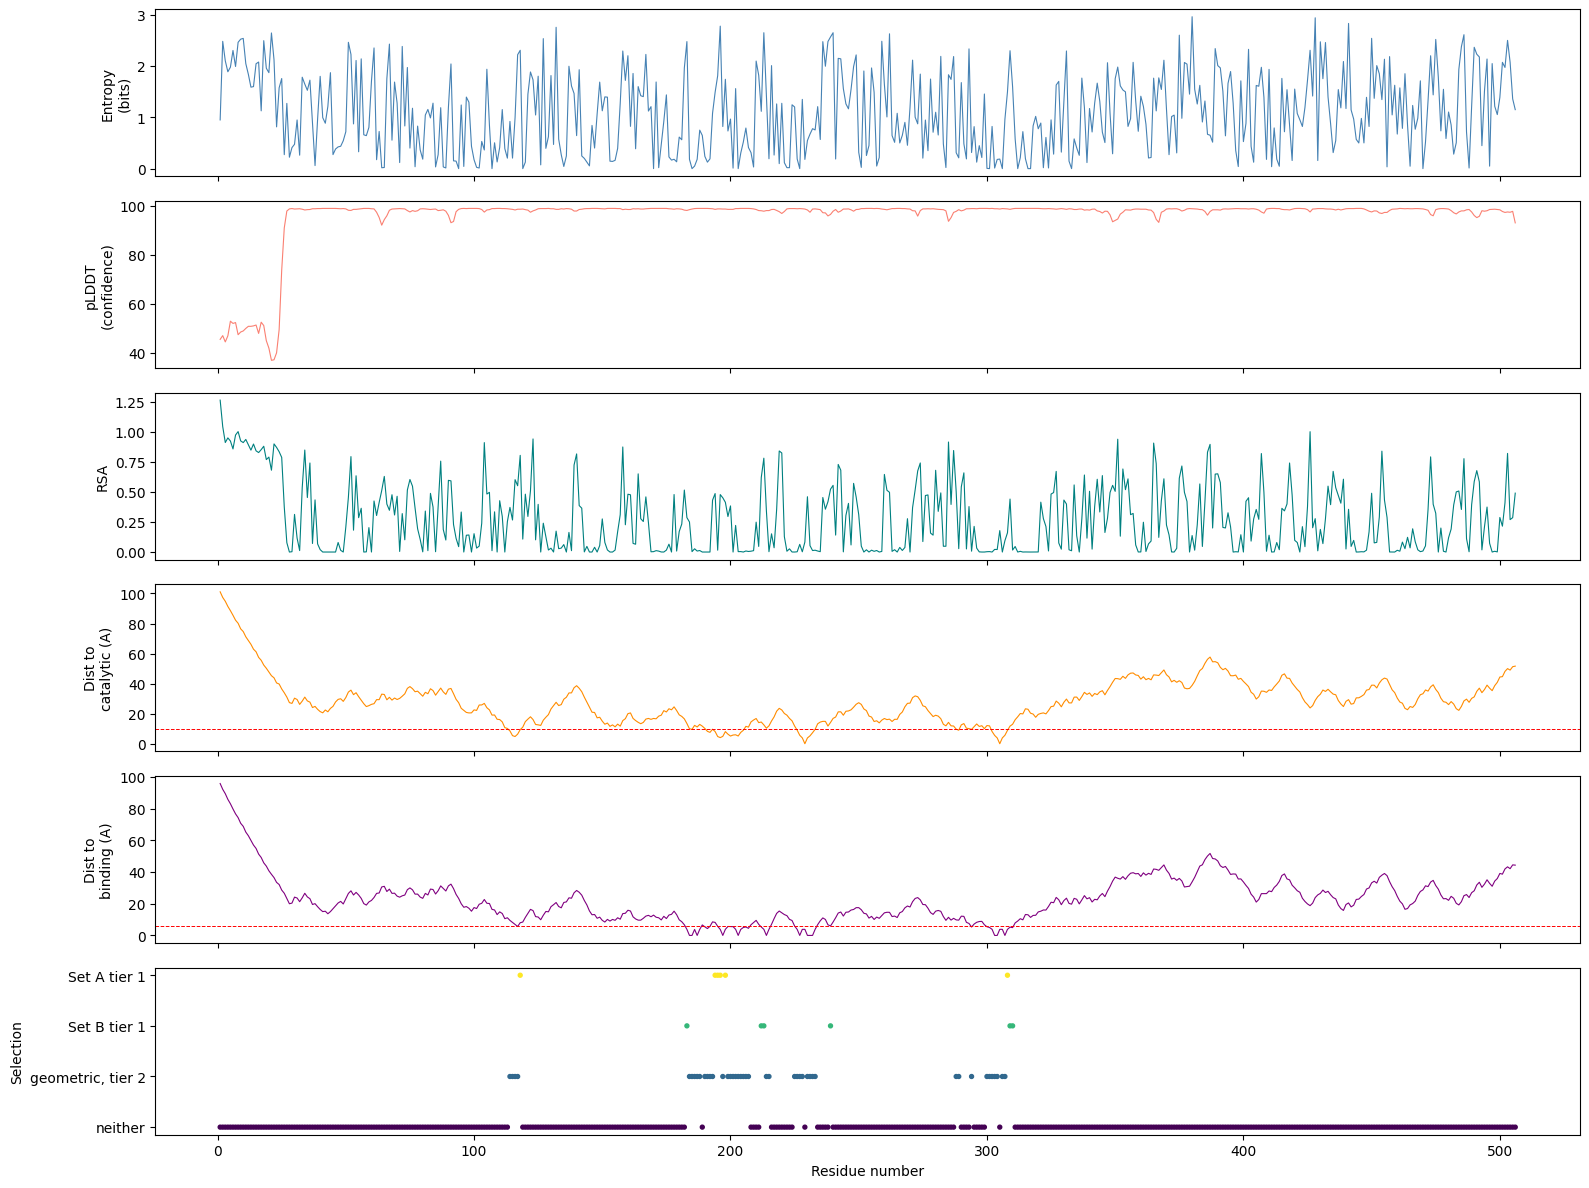

In [13]:
fig, axes = plt.subplots(6, 1, figsize=(16, 12), sharex=True)
x = master["residue_number"]

axes[0].plot(x, master["cons_shannon_entropy"], color="steelblue", lw=0.8)
axes[0].set_ylabel("Entropy\n(bits)")
if "struct_plddt" in master.columns:
    axes[1].plot(x, master["struct_plddt"], color="salmon", lw=0.8)
    axes[1].set_ylabel("pLDDT\n(confidence)")
else:
    axes[1].plot(x, master["struct_bfactor_ca_percentile"], color="salmon", lw=0.8)
    axes[1].set_ylabel("B-factor\npercentile")
axes[2].plot(x, master["struct_rsa"], color="teal", lw=0.8)
axes[2].set_ylabel("RSA")
axes[3].plot(x, master["struct_dist_nearest_catalytic"], color="darkorange", lw=0.8)
axes[3].axhline(CATALYTIC_RADIUS, color="red", linestyle="--", lw=0.7)
axes[3].set_ylabel("Dist to\ncatalytic (A)")
axes[4].plot(x, master["struct_dist_nearest_binding_site"], color="purple", lw=0.8)
axes[4].axhline(BINDING_RADIUS, color="red", linestyle="--", lw=0.7)
axes[4].set_ylabel("Dist to\nbinding (A)")

indicator = np.where(master["geom_set_a"] & (master["tier"]==1), 3,
             np.where(master["geom_set_b"] & (master["tier"]==1), 2,
             np.where(master["geom_set_a"] | master["geom_set_b"], 1, 0)))
axes[5].scatter(x, indicator, c=indicator, cmap="viridis", s=8)
axes[5].set_yticks([0, 1, 2, 3])
axes[5].set_yticklabels(["neither", "geometric, tier 2", "Set B tier 1", "Set A tier 1"])
axes[5].set_ylabel("Selection")
axes[5].set_xlabel("Residue number")

plt.tight_layout()
plt.savefig(fig_dir / "multitrack_position_plot.png", dpi=150)
plt.show()

## ddG vs natural frequency

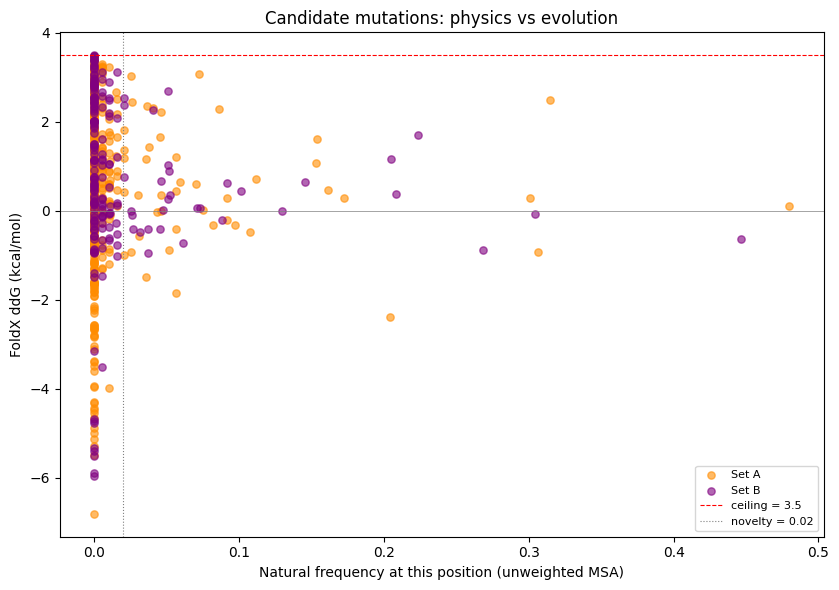

In [14]:
combined = pd.concat([muts_a, muts_b], ignore_index=True) if len(muts_a) or len(muts_b) else pd.DataFrame()
if len(combined):
    fig, ax = plt.subplots(figsize=(8.5, 6))
    for label, color in [("A", "darkorange"), ("B", "purple")]:
        s = combined[(combined["set"] == label) & combined["passes_ddg_ceiling"]]
        if len(s):
            ax.scatter(s["natural_frequency"], s["foldx_ddg"], c=color, alpha=0.6, s=28,
                       label=f"Set {label}")
    ax.axhline(0, color="grey", lw=0.5)
    ax.axhline(DDG_CEILING, color="red", linestyle="--", lw=0.8, label=f"ceiling = {DDG_CEILING}")
    ax.axvline(NOVELTY_THRESHOLD, color="grey", linestyle=":", lw=0.8,
               label=f"novelty = {NOVELTY_THRESHOLD}")
    ax.set_xlabel("Natural frequency at this position (unweighted MSA)")
    ax.set_ylabel("FoldX ddG (kcal/mol)")
    ax.set_title("Candidate mutations: physics vs evolution")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(fig_dir / "ddg_vs_natural_frequency.png", dpi=150)
    plt.show()

## Cross-target ddG comparison (predicted vs experimental structures)

FoldX ddG values are not necessarily comparable between a crystal structure and a predicted model. A deposited crystal structure is a real molecule carrying real strain; a predicted model is an idealised one, which FoldX's RepairPDB can relax further. The consequence is that apparently *stabilising* substitutions may be inflated on a predicted structure -- they partly reflect how much slack the model had, not how much the real protein would gain.

This compares the ddG distribution of the current target against any other target already processed, so the effect can be seen rather than assumed.

,target,structure,n_values,median,pct_stabilising,min,pct_above_ceiling
0,A1CGD1_A,predicted,10120,1.45,8.9,-8.88,29.1
1,1CTN_A,experimental,10760,1.43,7.9,-6.46,26.5
2,2JIE_A,experimental,8900,1.87,6.8,-3.50,30.8



Substitutions predicted stabilising (ddG < -0.5 kcal/mol):
   predicted structures:    8.9%
   experimental structures: 7.3%


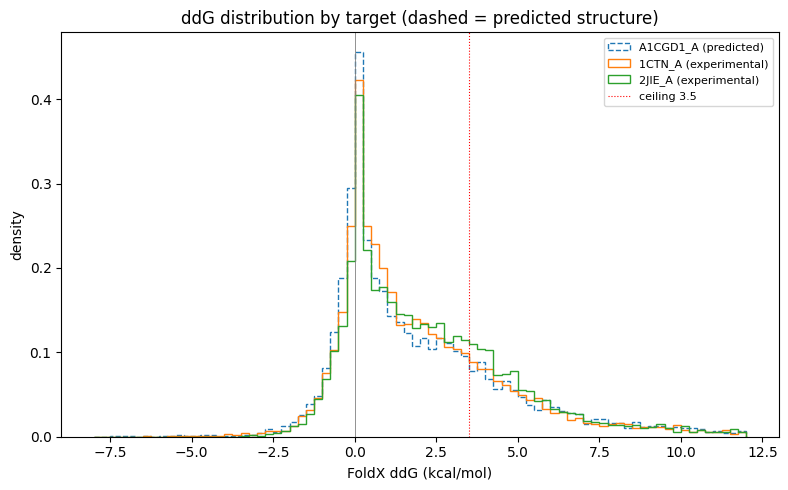

In [15]:
other_targets = sorted(p.name for p in results_dir.parent.iterdir()
                        if p.is_dir() and p.name != results_dir.name
                        and (p / "08_analysis" / "master_residue_table.csv").exists())

rows = []
def summarise(df, label, source):
    cols = [c for c in df.columns if c.startswith("foldx_ddg_")]
    v = df[cols].values.flatten()
    v = v[~np.isnan(v)]
    rows.append({
        "target": label, "structure": source, "n_values": len(v),
        "median": round(float(np.median(v)), 2),
        "pct_stabilising": round(float((v < -0.5).mean() * 100), 1),
        "min": round(float(v.min()), 2),
        "pct_above_ceiling": round(float((v > DDG_CEILING).mean() * 100), 1),
    })

this_source = "predicted" if "struct_plddt" in master.columns else "experimental"
summarise(master, results_dir.name, this_source)

for t in other_targets:
    try:
        other = pd.read_csv(results_dir.parent / t / "08_analysis" / "master_residue_table.csv")
        summarise(other, t, "predicted" if "struct_plddt" in other.columns else "experimental")
    except Exception as exc:
        print(f"  (skipped {t}: {exc})")

comparison = pd.DataFrame(rows)
display(comparison)

if len(comparison) > 1 and comparison.structure.nunique() > 1:
    pred = comparison[comparison.structure == "predicted"]["pct_stabilising"].mean()
    expt = comparison[comparison.structure == "experimental"]["pct_stabilising"].mean()
    print(f"\nSubstitutions predicted stabilising (ddG < -0.5 kcal/mol):")
    print(f"   predicted structures:    {pred:.1f}%")
    print(f"   experimental structures: {expt:.1f}%")
    if pred > expt * 1.5:
        print("\n   The gap is consistent with a predicted model carrying less strain than")
        print("   a real crystal, leaving more room for FoldX to find apparent gains.")
        print("   Treat strain-relief flags on a predicted structure with corresponding")
        print("   caution: they may reflect model idealisation rather than real headroom.")

if len(comparison) > 1:
    fig, ax = plt.subplots(figsize=(8, 5))
    for t in comparison.target:
        src = results_dir if t == results_dir.name else results_dir.parent / t
        df = master if t == results_dir.name else pd.read_csv(src / "08_analysis" / "master_residue_table.csv")
        cols = [c for c in df.columns if c.startswith("foldx_ddg_")]
        v = df[cols].values.flatten()
        v = v[~np.isnan(v)]
        style = "--" if "struct_plddt" in df.columns else "-"
        ax.hist(v, bins=80, range=(-8, 12), histtype="step", linestyle=style,
                density=True, label=f"{t} ({'predicted' if style=='--' else 'experimental'})")
    ax.axvline(0, color="grey", lw=0.6)
    ax.axvline(DDG_CEILING, color="red", ls=":", lw=0.8, label=f"ceiling {DDG_CEILING}")
    ax.set_xlabel("FoldX ddG (kcal/mol)")
    ax.set_ylabel("density")
    ax.set_title("ddG distribution by target (dashed = predicted structure)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(fig_dir / "ddg_distribution_by_target.png", dpi=150)
    plt.show()

## Summary statistics

Structural percentages use modeled residues only as denominator.

In [16]:
modeled = master[master["is_modeled_in_structure"]]
all_lib = pd.concat([lib_a, lib_b]) if len(lib_a) or len(lib_b) else pd.DataFrame()

summary = {
    "sequence_length": len(master),
    "residues_modeled_in_structure": len(modeled),
    "uniprot_structure_conflicts": int(master["uniprot_structure_conflict"].sum()),
    "pct_helix": (modeled["struct_ss_class"] == "helix").mean() * 100,
    "pct_sheet": (modeled["struct_ss_class"] == "sheet").mean() * 100,
    "pct_loop": (modeled["struct_ss_class"] == "loop").mean() * 100,
    "pct_buried": (modeled["struct_burial_class"] == "buried").mean() * 100,
    "pct_exposed": (modeled["struct_burial_class"] == "exposed").mean() * 100,
    "set_a_geometric_positions": int(master["geom_set_a"].sum()),
    "set_b_geometric_positions": int(master["geom_set_b"].sum()),
    "set_a_tier1_positions": int((master["geom_set_a"] & (master["tier"]==1)).sum()),
    "set_b_tier1_positions": int((master["geom_set_b"] & (master["tier"]==1)).sum()),
    "set_a_library_variants": len(lib_a),
    "set_b_library_variants": len(lib_b),
    "total_library_variants": len(lib_a) + len(lib_b),
    "novel_substitutions_in_library": int(all_lib.is_novel_substitution.sum()) if len(all_lib) else 0,
}
summary_df = pd.DataFrame([summary]).T.rename(columns={0: "value"})
summary_df.to_csv(table_dir / "summary_statistics.csv")
summary_df

,value
sequence_length,506.000000
residues_modeled_in_structure,506.000000
uniprot_structure_conflicts,0.000000
pct_helix,10.474308
pct_sheet,36.758893
pct_loop,52.766798
pct_buried,35.177866
pct_exposed,45.454545
set_a_geometric_positions,38.000000
set_b_geometric_positions,17.000000
